# Identifying a multi-particle battery model with linearised electrolyte from cycler data alone
**Digital version of the paper.**

This notebook reproduces the results of Section 3 with the code, data and identified parameter sets of this
repository: the paper's Figs. 4, 8, 9 and 10 and Tables 2–9, for the Mohtat NMC532/graphite pouch cells
(Sections 3.1–3.6) and for the second cell type, the LG M50T NMC811/graphite–SiOx cylindrical cell (Section 3.7). It
shows only the paper's figures and tables.

By default every result is computed from the saved parameter sets (no fit). Set `RUN_FITS = True` to rerun step 1
and the joint fit of the chosen case, which takes about 40 min on a GPU. The figures are made by the same scripts
as in the paper (`scripts/`). The first run simulates all 18 held-out cells (a few minutes on a GPU, longer on a
CPU).

In [1]:
import os, sys, json, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = os.path.abspath('.')
sys.path[:0] = [ROOT, os.path.join(ROOT, 'scripts')]
from srcs import study as S, identification as ident
CASES = {'A': 'fitA', 'B': 'fitB', 'C': 'caseC'}
RUN_FITS = False            # True: rerun step 1 and step 2 of case B (slow)
FIG = os.path.join(ROOT, 'figures')

def paper_figure(script, out, *args):
    """Make a paper figure with its own script (unless it exists) and show it."""
    png = os.path.join(FIG, out + '.png')
    if not os.path.exists(png):
        subprocess.run([sys.executable, os.path.join(ROOT, 'scripts', script), *args, '--out', os.path.join(FIG, out)], check=True, cwd=ROOT)
    display(Image(png, width=900))

st = {k: S.load(os.path.join(ROOT, 'configs', v + '.json')) for k, v in CASES.items()}
B = st['B']
print('calibration cells:', B.split['dynamics'], '| held-out cells:', B.split['validation'])

calibration cells: ['C07', 'C08', 'C09'] | held-out cells: ['C01', 'C02', 'C03', 'C04', 'C05', 'C06', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21']


## 3.1 Dataset, calibration cells and cases
**Table 2.** Cells by ageing protocol (charge / discharge rate, depth of discharge, DoD) and chamber temperature. The
calibration cells are 07, 08 and 09.

In [2]:
protocols = ['C/5 / C/5, 100 %', '1.5C / 1.5C, 100 %', '2C / 2C, 100 %', 'C/5 / 1.5C, 100 %', 'C/5 / C/5, 50 %',
             'C/5 / 1.5C, 50 %', '1.5C / drive cycle, 50 %']
tab2 = pd.DataFrame([[f'{3*i+2:02d}', f'{3*i+1:02d}', f'{3*i+3:02d}'] for i in range(7)], index=protocols, columns=['-5 C', '25 C', '45 C'])
tab2.map(lambda c: c + ' (cal.)' if 'C' + c in B.split['dynamics'] else c)

,-5 C,25 C,45 C
"C/5 / C/5, 100 %",02,01,03
"1.5C / 1.5C, 100 %",05,04,06
"2C / 2C, 100 %",08 (cal.),07 (cal.),09 (cal.)
"C/5 / 1.5C, 100 %",11,10,12
"C/5 / C/5, 50 %",14,13,15
"C/5 / 1.5C, 50 %",17,16,18
"1.5C / drive cycle, 50 %",20,19,21


## 3.2 Step 1: OCV and electrode windows
**Fig. 4.** The window groups (cell 07, its own window). (a) Stoichiometries of the two electrodes against the
discharged charge. Solid: the window the cell uses, from x100 and y100 at full charge to x0 and y0 at the end of
discharge, over the cell capacity Q. Dashed, outside the window (shaded): the same lines extended to x = 1 and 0
and to y = 0 and 1. The charges between these ends are the electrode capacities Q_n and Q_p. (b) Open-circuit
potentials of the two electrodes against stoichiometry. (c) The two potentials and the open-circuit voltage
U_p(y) − U_n(x) over the window.

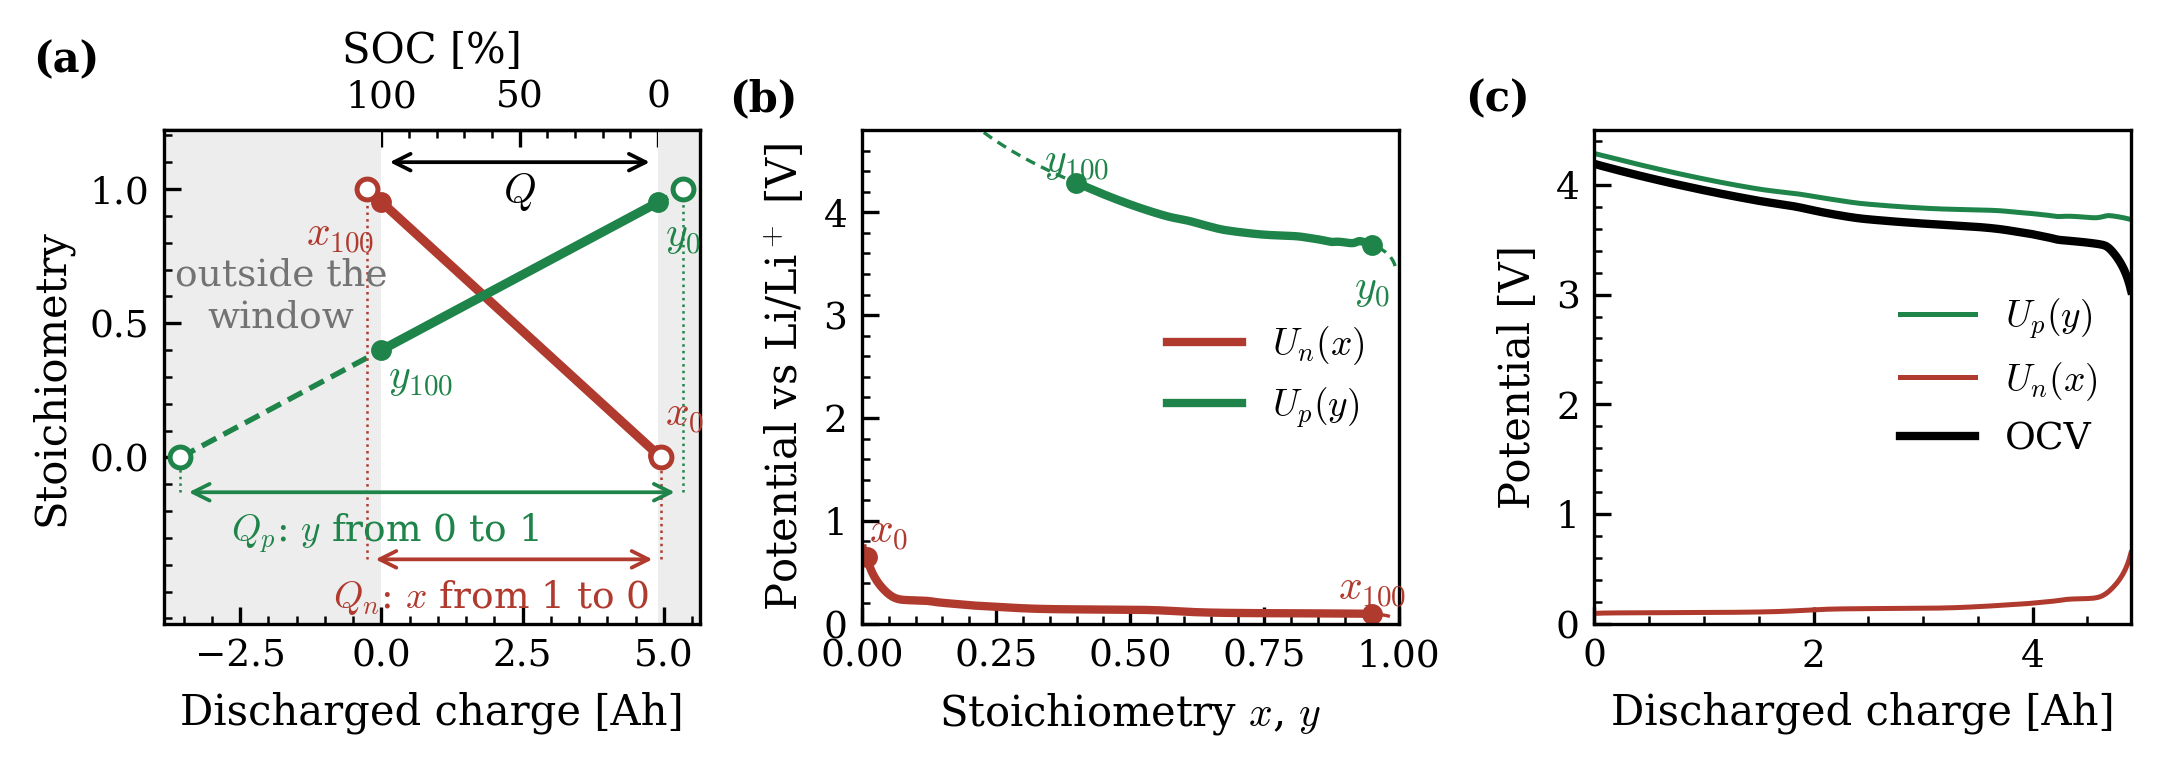

In [3]:
if RUN_FITS:
    subprocess.run([sys.executable, 'scripts/step1_window.py', 'configs/fitB.json'], check=True, cwd=ROOT)
    subprocess.run([sys.executable, 'scripts/anchor_window.py', 'fitB', 'fitB'], check=True, cwd=ROOT)   # common window
paper_figure('fig_groups.py', 'fig4_window_groups', '--study', 'fitB', '--cell', 'C07')

**Table 3.** Electrode window with the generic anode OCP (cases B and C). The stoichiometric limits are common to
all cells. Q_n and Q_p follow from the C/20 capacity of each cell; the ranges are those of the three calibration
cells.

In [4]:
W = B.windows(); cal = B.split['dynamics']
w = pd.DataFrame({c: W[c] for c in cal}).T
pd.Series({'x100': '%.3f' % w.x100.mean(), 'x0': '%.3f' % w.x0.mean(), 'y100 (assumed)': '%.3f' % w.y100.mean(), 'y0 (assumed)': '%.3f' % w.y0.mean(),
           'Q, C/20 capacity [A h]': '%.2f-%.2f' % (w.q_ocv_Ah.min(), w.q_ocv_Ah.max()),
           'Q_n [A h]': '%.2f-%.2f' % (w.Q_n.min(), w.Q_n.max()), 'Q_p [A h]': '%.2f-%.2f' % (w.Q_p.min(), w.Q_p.max()),
           'mean capacity of the calibration cells (case C) [A h]': '%.3f' % w.q_ocv_Ah.mean()}).to_frame('Window')

,Window
x100,0.951
x0,0.009
y100 (assumed),0.400
y0 (assumed),0.950
"Q, C/20 capacity [A h]",4.80-4.90
Q_n [A h],5.09-5.20
Q_p [A h],8.72-8.90
mean capacity of the calibration cells (case C) [A h],4.836


## 3.3 Selection of the groups
**Table 4.** The thirteen candidate groups at 25 °C, their local sensitivity S_j of the voltage of the HPPC, the
C/20 and the first cycle of cell 07 (per unit ln p, median over 40 points of the ±10 % box around the
pre-calibration), their most correlated group (median |ρ|) and the decision of Section 3.3 (S_j below 5 mV:
fixed; above 15 mV: fitted; in between, fitted only if its correlation with every other candidate stays below 0.5). To rerun the screening:
`python scripts/fit_lm.py configs/precalibration.json --fresh`, then
`python scripts/screening_local.py screening precalibration --r 40 --wmin 0.1`.

In [5]:
scr = json.load(open('runs/screening/screening_local/screening_local.json'))
names = scr['names']; Rm = np.array(scr['corr_median'], float)
gB = B.load('dynamics.json')['groups']; fitted = B.cfg['dynamics']['names']
DECISION = {n: 'fitted' if n in fitted else 'fixed (%.4g)' % gB[n] for n in names if n in gB}
rows = []
for i, n in enumerate(names):
    if n == 'R_contact':            # not in the model of the paper
        continue
    r = np.abs(Rm[i].copy()); r[i] = -1; r[names.index('R_contact')] = -1; j = int(np.nanargmax(r))
    rows.append(dict(group=n, **{'S_j [mV]': scr['S_local_mV'][n][1],
                'most correlated with (rho)': '%s (%+.2f)' % (names[j], Rm[i, j]), 'in the fit': DECISION.get(n, '')}))
pd.DataFrame(rows).set_index('group').sort_values('S_j [mV]', ascending=False).round(1)

,S_j [mV],most correlated with (rho),in the fit
group,,,
R_e,41.8,De_f (+0.82),fitted
theta_p,34.8,theta_n (-0.67),fitted
De_f,31.3,R_e (+0.82),fitted
I0_p,20.0,theta_n (+0.25),fitted
theta_n,18.1,theta_p (-0.67),fitted
eps_p,13.3,eps_n (+0.83),fitted
brugg,11.2,L_e (-0.75),fixed (1.5)
eps_n,10.9,eps_p (+0.83),fixed (0.3892)
L_e,9.7,brugg (-0.75),fixed (0.000141)


## 3.4 Final fit
**Table 5.** Identified groups at 25 °C in cases A and B (case C takes those of B). The diffusion times are fitted at
0 °C and converted to 25 °C with their activation energies. The groups fixed in both cases are printed below the table.

In [6]:
if RUN_FITS:
    subprocess.run([sys.executable, 'scripts/fit_lm.py', 'configs/fitB.json', '--fresh'], check=True, cwd=ROOT)
arr = lambda th, ea: th * np.exp(-ea / 8.314462618 * (1 / 273.15 - 1 / 298.15))     # theta at 0 C -> 25 C
LABEL = {'theta_n': 'theta_n [s]', 'theta_p': 'theta_p [s]', 'I0_p': 'I0_p [A]', 'R_e': 'R_e [mOhm]', 'r_np': 'r_np',
         'eps_n': 'eps_n', 'eps_p': 'eps_p', 'De_f': 'f_De', 'Ea_Dn': 'E_a,D,n [kJ/mol]', 'Ea_Dp': 'E_a,D,p [kJ/mol]',
         'Ea_r': 'E_a,r [kJ/mol]', 'dUdT0': 'gamma0 [mV/K]', 'dEa_De': 'dE_a,De [kJ/mol]'}
SCALE = {'R_e': 1e3, 'Ea_Dn': 1e-3, 'Ea_Dp': 1e-3, 'Ea_r': 1e-3, 'dUdT0': 1e3, 'dEa_De': 1e-3}
rows = {}
for k in ('A', 'B'):
    d = st[k].load('dynamics.json'); g = d['groups']
    r = {LABEL.get(n, n): g[n] * SCALE.get(n, 1.0) for n in st[k].cfg['dynamics']['names']}
    r['theta_n [s]'], r['theta_p [s]'] = arr(g['theta_n'], g['Ea_Dn']), arr(g['theta_p'], g['Ea_Dp'])
    rows['case ' + k] = {**r, 'cost of the fit [mV]': d['cost_mV']}
gB = st['B'].load('dynamics.json')['groups']
print('fixed:', ', '.join('%s = %.4g' % (n, gB[n]) for n in ('I0_n', 'L_e', 'eps_n', 'eps_s', 'l_s', 'brugg')
                          if n not in st['B'].cfg['dynamics']['names']))
pd.DataFrame(rows).round(3)

fixed: I0_n = 1229, L_e = 0.000141, eps_n = 0.3892, eps_s = 0.4023, l_s = 0.1494, brugg = 1.5


,case A,case B
theta_n [s],167.952,666.338
theta_p [s],277.260,287.984
I0_p [A],2.967,4.107
R_e [mOhm],1.579,1.719
"E_a,D,n [kJ/mol]",61.618,67.708
"E_a,D,p [kJ/mol]",41.236,39.663
"E_a,r [kJ/mol]",35.024,44.600
gamma0 [mV/K],0.356,0.390
eps_p,0.424,0.336
r_np,0.422,0.385


## 3.5 Prediction of the held-out cells
**Fig. 8.** Measured and predicted voltage of the first cycle of fifteen held-out cells in the three cases. Columns:
chamber at −5, 25 and 45 °C. Rows: C/5 charge and discharge, 50 % depth of discharge (a–c: cells 14, 13, 15); C/5
charge and discharge, 100 % (d–f: cells 02, 01, 03); 1.5C charge and discharge, 100 % (g–i: cells 05, 04, 06); C/5
charge and 1.5C discharge, 100 % (j–l: cells 11, 10, 12); 1.5C charge and drive-cycle discharge, 50 % (m–o: cells 20,
19, 21). Inset: 12 min of the cold drive cycle (m).

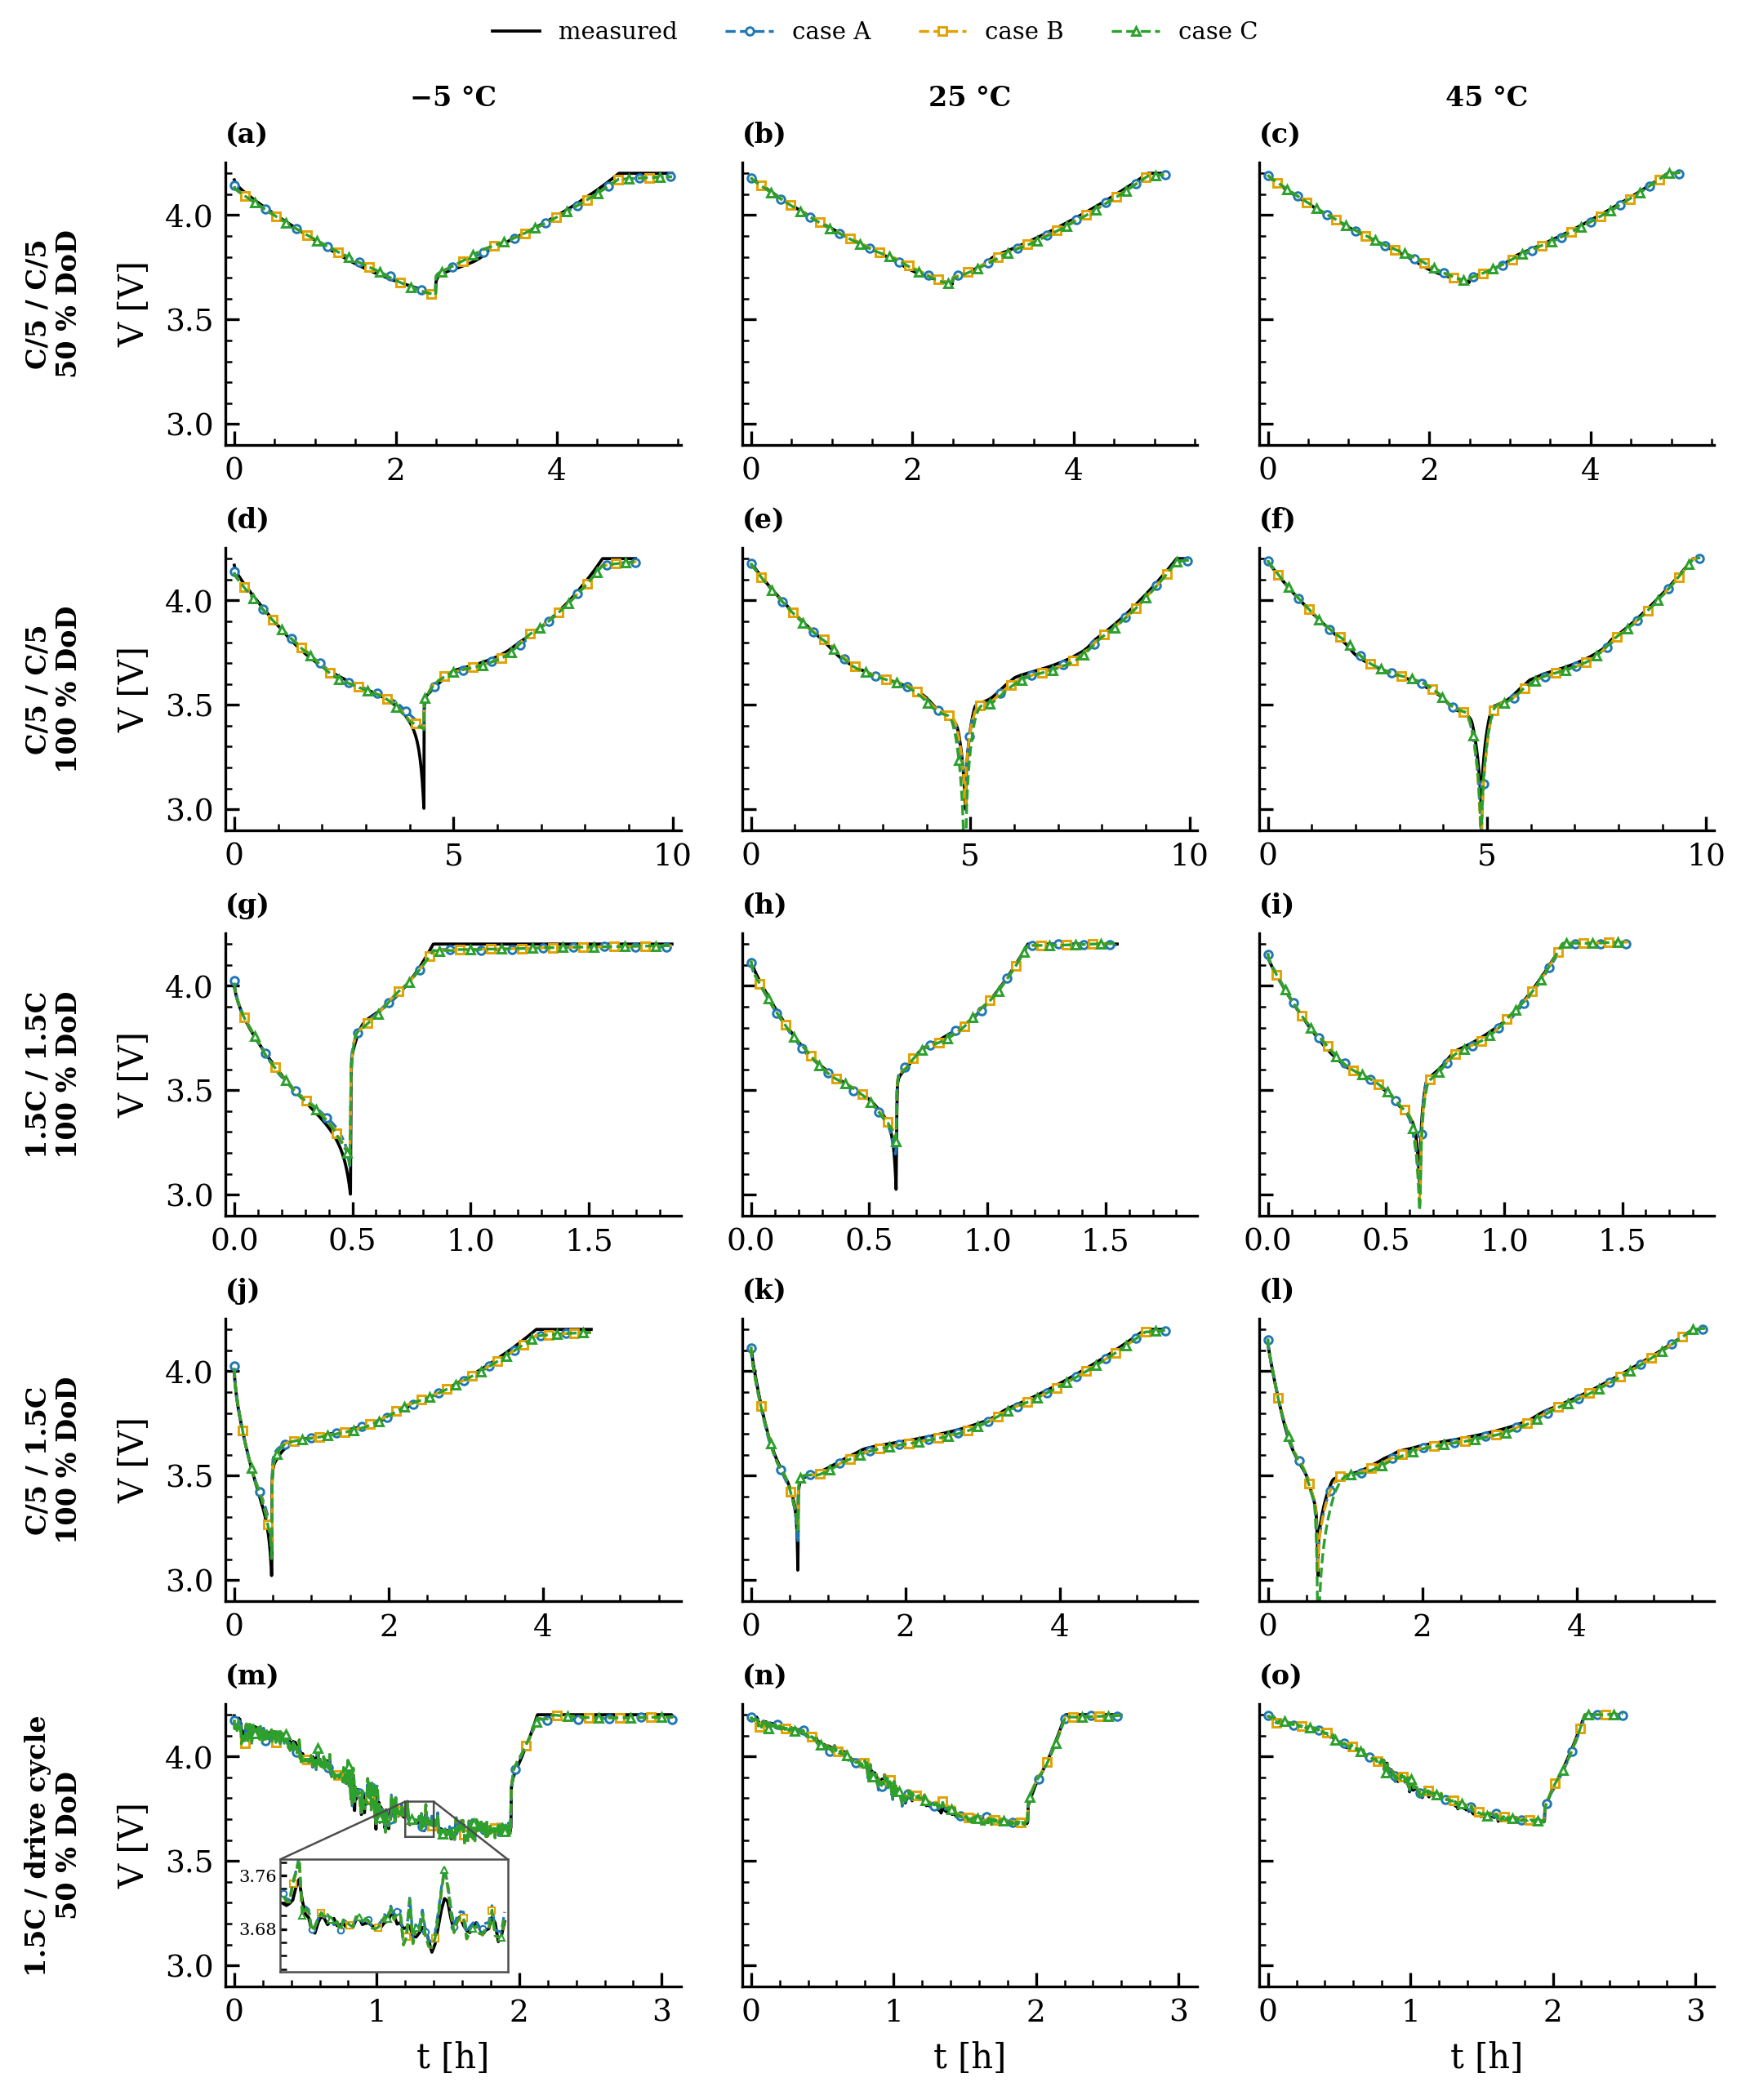

In [7]:
paper_figure('fig_cases_grid.py', 'fig8_voltage_grid', '--cases', *['%s:%s' % kv for kv in CASES.items()])

**Table 6.** Held-out error of the three cases: RMSE over the whole first cycle, averaged over the held-out cells at
each chamber temperature (six at each temperature), and the cell with the largest RMSE.

In [8]:
import fig_cases_heldout as H
ho = {k: H.heldout(v).set_index('cell') for k, v in CASES.items()}
tab6 = {}
for k, d in ho.items():
    by = d.groupby('T_group').rmse_mV.mean()
    tab6['case ' + k] = {'RMSE at -5 / 25 / 45 C [mV]': '%.1f / %.1f / %.1f' % (by[-5], by[25], by[45]),
                         'mean / worst cell [mV]': '%.1f / %.1f (cell %s)' % (d.rmse_mV.mean(), d.rmse_mV.max(), d.rmse_mV.idxmax()[1:])}
pd.DataFrame(tab6)

,case A,case B,case C
RMSE at -5 / 25 / 45 C [mV],20.5 / 10.3 / 10.6,20.3 / 12.3 / 10.6,19.6 / 28.6 / 19.4
mean / worst cell [mV],13.8 / 32.7 (cell 02),14.4 / 31.3 (cell 02),22.5 / 112.6 (cell 01)


**Fig. 9.** Held-out error of the three cases. (a) First-cycle RMSE of each of the 18 held-out cells, grouped by
chamber temperature. (b–d) RMSE of the scored samples in each bin (marker) and 5–95 % of the absolute error
(whisker), binned by C-rate, state of charge and chamber temperature; bins with fewer than 30 samples omitted.
No refit.

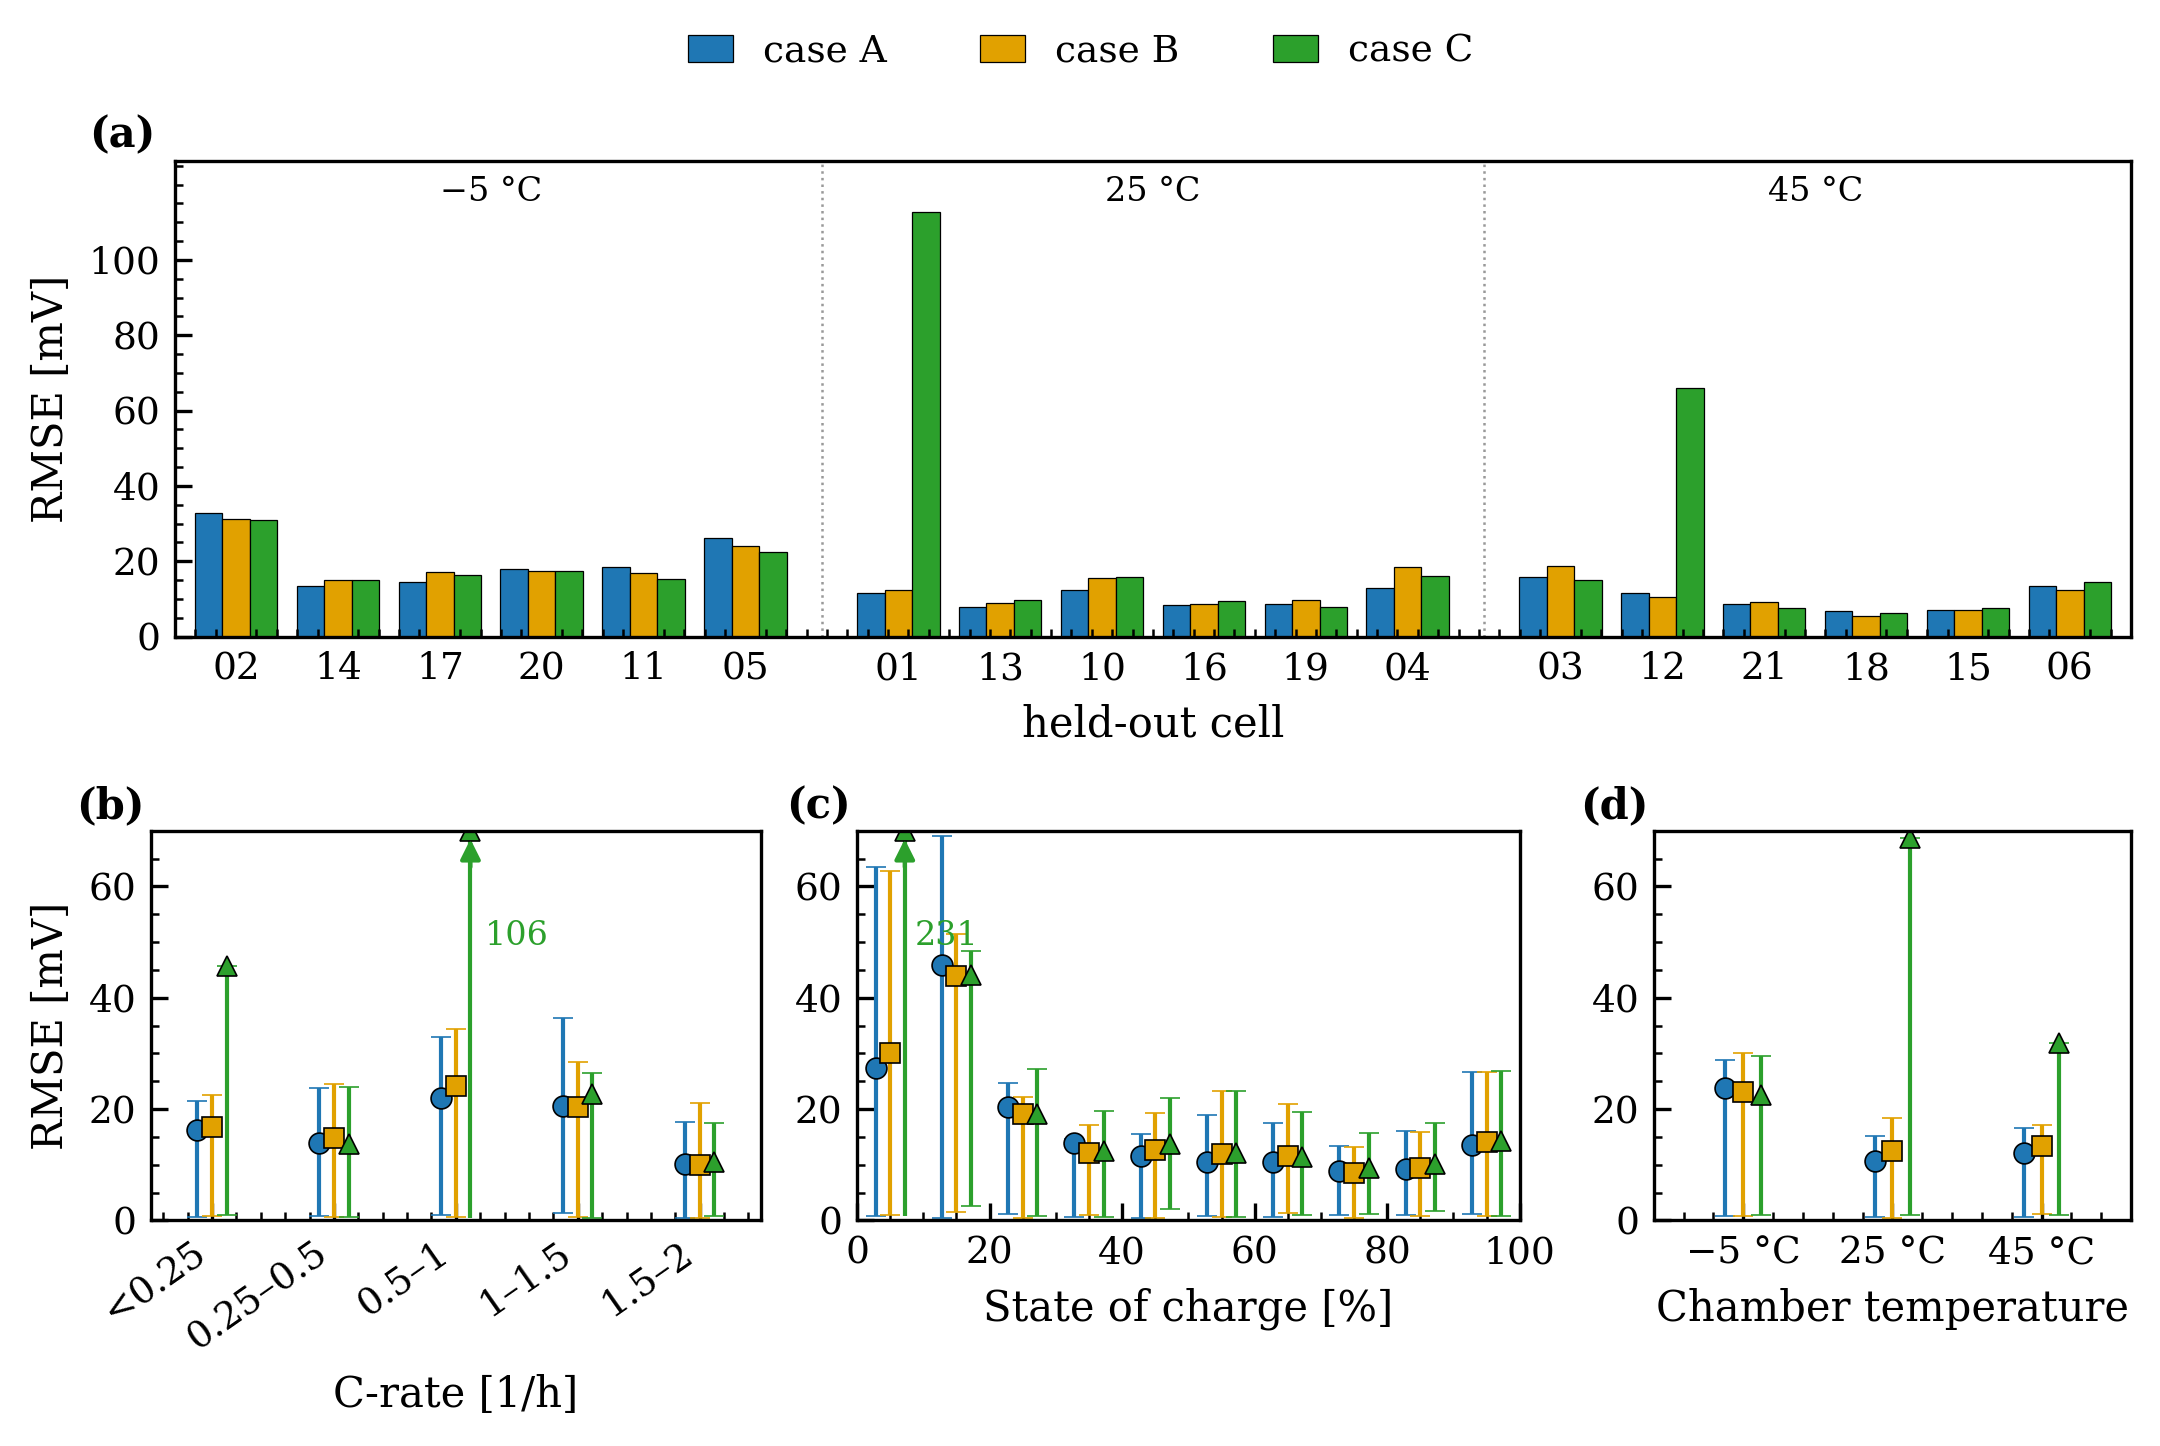

In [9]:
if not os.path.exists(os.path.join(FIG, 'fig9_heldout_errors.png')):      # the error samples of each case first
    subprocess.run([sys.executable, 'scripts/error_bins.py', *['configs/%s.json' % v for v in CASES.values()], '--out', 'runs'], check=True, cwd=ROOT)
paper_figure('fig_cases_errors.py', 'fig9_heldout_errors', '--cases', *['%s:%s' % kv for kv in CASES.items()])

**Table 7.** Online capacity of the held-out cells whose first discharge reaches the cutoff (case C, capacity
calibrated online): the factor s_Q on Q_n and Q_p fitted on the first discharge against the one from the C/20
(relative to the mean capacity of the calibration cells), and the RMSE of the whole first cycle with the mean
capacity, with s_Q and with the C/20 (case B).

In [10]:
cap = pd.read_csv('results/online_capacity_C.csv').set_index('cell')
cap = cap[cap.V_end_first < 3.2]
pd.DataFrame({'T [C]': cap.T_C.round(0), 's_Q, first discharge': cap.s_fit.round(3), 's_Q, C/20': cap.s_c20.round(3),
              'RMSE, mean capacity [mV]': cap.all_mean.round(1), 'RMSE, s_Q [mV]': cap.all_fit.round(1), 'RMSE, C/20 [mV]': cap.all_c20.round(1)})

,T [C],"s_Q, first discharge","s_Q, C/20","RMSE, mean capacity [mV]","RMSE, s_Q [mV]","RMSE, C/20 [mV]"
cell,,,,,,
C01,23.0,1.013,1.013,84.8,12.3,12.3
C02,-4.0,0.960,1.004,30.4,23.8,30.6
C03,44.0,1.003,0.996,11.9,12.3,18.7
C04,30.0,0.981,1.005,17.7,12.1,19.0
C05,-1.0,0.975,1.004,20.8,17.8,21.9
C06,48.0,1.005,1.001,12.1,12.4,11.9
C10,25.0,0.977,1.002,15.8,20.0,15.6
C12,45.0,1.016,1.015,38.9,10.1,10.4


## 3.6 Which signals the identification needs
**Table 8.** Ablation of the first cycles fitted with the base (the HPPC and the C/20 of cell 07), case B refitted
from scratch on each set. Held-out: mean first-cycle RMSE over the 15 cells that no set uses.

In [11]:
ab = json.load(open('results/abl_summary.json'))
pd.DataFrame({','.join(c[1:] for c in v['cells']): {'cost [mV]': round(v['cost_mV'], 1), 'held-out, mean [mV]': round(v['heldout_mean'], 1),
              'held-out at -5 / 25 / 45 C [mV]': ' / '.join('%.1f' % v['heldout_T'][T] for T in ('-5', '25', '45'))}
              for v in ab.values()}).T

,cost [mV],"held-out, mean [mV]",held-out at -5 / 25 / 45 C [mV]
"07,08,09",16.6,12.5,16.6 / 12.4 / 10.5
"07,09,11",16.1,12.6,17.2 / 12.2 / 10.7
"07,08,09,11",16.9,12.6,17.1 / 12.3 / 10.6
"07,08,09,05",18.1,12.8,18.3 / 12.2 / 10.6
"07,08,09,02",20.1,12.8,18.7 / 12.3 / 10.4
"07,08,09,11,02",19.9,12.8,18.2 / 12.6 / 10.3


## 3.7 A second cell type
The LG M50T (21700, NMC811 / graphite–SiOx, 5 A h) of the dataset of Kirkaldy et al. (Expt 4: drive-cycle ageing,
WLTP discharges; Expt 5: 1C cycling; chambers at 10, 25 and 40 °C). The same pipeline runs with one term added, the
OCV hysteresis of the silicon-blended anode, measured in step 1 from the C/10 cycle and the GITT rests
(`scripts/hysteresis_c10_gitt.py`). Cases: `lgA` (anode OCP of the cell itself, from half-cell measurements),
`lgB` (generic blended graphite–Si anode), `lgC` (groups of B, mean capacity of the calibration cells).

In [12]:
LG = {'A': 'lgA', 'B': 'lgB', 'C': 'lgC'}
lst = {k: S.load(os.path.join(ROOT, 'configs', v + '.json')) for k, v in LG.items()}
LB = lst['B']
print('calibration cells:', LB.split['dynamics'], '| held-out cells:', LB.split['validation'])
print('fitted tests:', ['%s %s' % (t['test'], ','.join(t.get('cells', []))) for t in LB.cfg['dynamics']['tests']])

calibration cells: ['E4A', 'E4D', 'E4F', 'E5A', 'E5D', 'E5F'] | held-out cells: ['E4B', 'E4E', 'E4G', 'E5B', 'E5E', 'E5G']
fitted tests: ['VAL E5A,E5D,E5F', 'GITT E4D', 'C10 E4D']


**Table 9.** LG M50T: screening at 25 °C and final fit. S_j: local sensitivity at the pre-calibrated optimum
(median over the screening box) and the candidate most correlated with it (median ρ). Value: fitted, or frozen at
the pre-calibration; diffusion times converted to 25 °C. To rerun step 0:
`python scripts/fit_lm.py configs/lg_precalibration.json --fresh`, then
`python scripts/screening_local.py lg_screening lg_precalibration --r 40 --wmin 0.1` and
`python scripts/select_groups_rule.py runs/screening/lg_screening_local/screening_local.json configs/lg_precalibration.json configs/lgB.json lgB`.

In [13]:
if RUN_FITS:
    subprocess.run([sys.executable, 'scripts/step1_window.py', 'configs/lgB.json'], check=True, cwd=ROOT)
    subprocess.run([sys.executable, 'scripts/mean_window.py', 'configs/lgB.json'], check=True, cwd=ROOT)    # common window
    subprocess.run([sys.executable, 'scripts/hysteresis_c10_gitt.py', 'configs/lgB.json'], check=True, cwd=ROOT)
    subprocess.run([sys.executable, 'scripts/fit_lm.py', 'configs/lgB.json', '--fresh'], check=True, cwd=ROOT)
scr = json.load(open('runs/screening/lg_screening_local/screening_local.json'))
names = scr['names']; Rm = np.array(scr['corr_median'], float)
dB = LB.load('dynamics.json'); g = dB['groups']; fitted = LB.cfg['dynamics']['names']
T0 = float(LB.cfg['model'].get('theta_ref_C', 25.0)) + 273.15
to25 = lambda th, ea: th * np.exp(-ea / 8.314462618 * (1 / T0 - 1 / 298.15))   # theta at theta_ref -> 25 C
val = {**LB.cfg['dynamics']['fixed'], **g}
val['theta_n'], val['theta_p'] = to25(g['theta_n'], g['Ea_Dn']), to25(g['theta_p'], g['Ea_Dp'])
UNIT = {'R_e': ('R_e [mOhm]', 1e3), 'L_e': ('L_e [um]', 1e6), 'Ea_Dn': ('E_a,D,n [kJ/mol]', 1e-3), 'Ea_Dp': ('E_a,D,p [kJ/mol]', 1e-3),
        'Ea_r': ('E_a,r [kJ/mol]', 1e-3), 'dUdT0': ('gamma0 [mV/K]', 1e3), 'dEa_De': ('dE_a,De [kJ/mol]', 1e-3),
        'theta_n': ('theta_n [s]', 1), 'theta_p': ('theta_p [s]', 1), 'I0_n': ('I0_n [A]', 1), 'I0_p': ('I0_p [A]', 1), 'De_f': ('f_De', 1)}
lb, ub = dict(zip(fitted, LB.cfg['dynamics']['lb'])), dict(zip(fitted, LB.cfg['dynamics']['ub']))
on_bound = lambda n: n in fitted and min(abs(g[n] - lb[n]), abs(ub[n] - g[n])) < 1e-3 * abs(ub[n] - lb[n])
rows = []
for i, n in enumerate(names):
    r = np.abs(Rm[i].copy()); r[i] = -1; j = int(np.nanargmax(r))
    lab, sc = UNIT.get(n, (n, 1))
    rows.append({'group': lab, 'S_j [mV]': round(scr['S_local_mV'][n][1], 1), 'most correlated (rho)': '%s (%+.2f)' % (names[j], Rm[i, j]),
                 'in the fit': ('fitted (bound)' if on_bound(n) else 'fitted') if n in fitted else 'fixed', 'value at 25 C': '%.4g' % (val[n] * sc)})
for n in ('Ea_Dn', 'Ea_Dp', 'Ea_r', 'dUdT0', 'dEa_De'):
    lab, sc = UNIT[n]
    rows.append({'group': lab, 'S_j [mV]': '', 'most correlated (rho)': '', 'in the fit': 'fitted (bound)' if on_bound(n) else 'fitted',
                 'value at 25 C': '%.4g' % (g[n] * sc)})
print('cost of the fit: %.1f mV' % dB['cost_mV'])
pd.DataFrame(rows).set_index('group')

cost of the fit: 38.5 mV


,S_j [mV],most correlated (rho),in the fit,value at 25 C
group,,,,
theta_n [s],73.7,theta_p (-0.49),fitted,1.141e+04
theta_p [s],7.4,theta_n (-0.49),fitted (bound),73.45
I0_n [A],16.0,I0_p (-0.72),fitted,1.306
I0_p [A],12.5,I0_n (-0.72),fixed,2.714
R_e [mOhm],21.8,De_f (+0.99),fitted,4.915
eps_n,3.3,eps_p (+0.91),fixed,0.3297
eps_p,2.7,eps_n (+0.91),fixed,0.4984
r_np,3.7,brugg (-0.44),fixed,0.5834
f_De,11.9,R_e (+0.99),fixed,0.5422


**Held-out error.** RMSE of the six held-out cells (WLTP part of the first cycles for the drive-cycle cells E4B,
E4E, E4G; first 1C cycle for E5B, E5E, E5G), per case.

In [14]:
lho = {k: H.heldout(v).set_index('cell') for k, v in LG.items()}
pd.DataFrame({'case ' + k: {**d.rmse_mV.round(1).to_dict(), 'mean': round(d.rmse_mV.mean(), 1)} for k, d in lho.items()})

,case A,case B,case C
E4B,17.9,21.7,19.7
E4E,31.0,32.2,25.8
E4G,34.4,34.7,29.8
E5B,15.4,16.0,14.8
E5E,15.3,13.7,15.4
E5G,17.8,15.8,20.0
mean,22.0,22.4,20.9


**Fig. 10.** Measured and predicted voltage of the six held-out LG M50T cells in cases A, B and C. Rows:
drive-cycle experiment (first WLTP cycles; a–c: cells E4B, E4E, E4G) and 1C experiment (first 1C cycle; d–f: cells
E5B, E5E, E5G). Columns: chamber at 10, 25 and 40 °C; each panel starts 15 min before the first discharge. (g) RMSE of
each held-out cell, grouped by chamber temperature: E4B, E4E and E4G are the drive-cycle (WLTP) cells, E5B, E5E and
E5G the 1C cells.

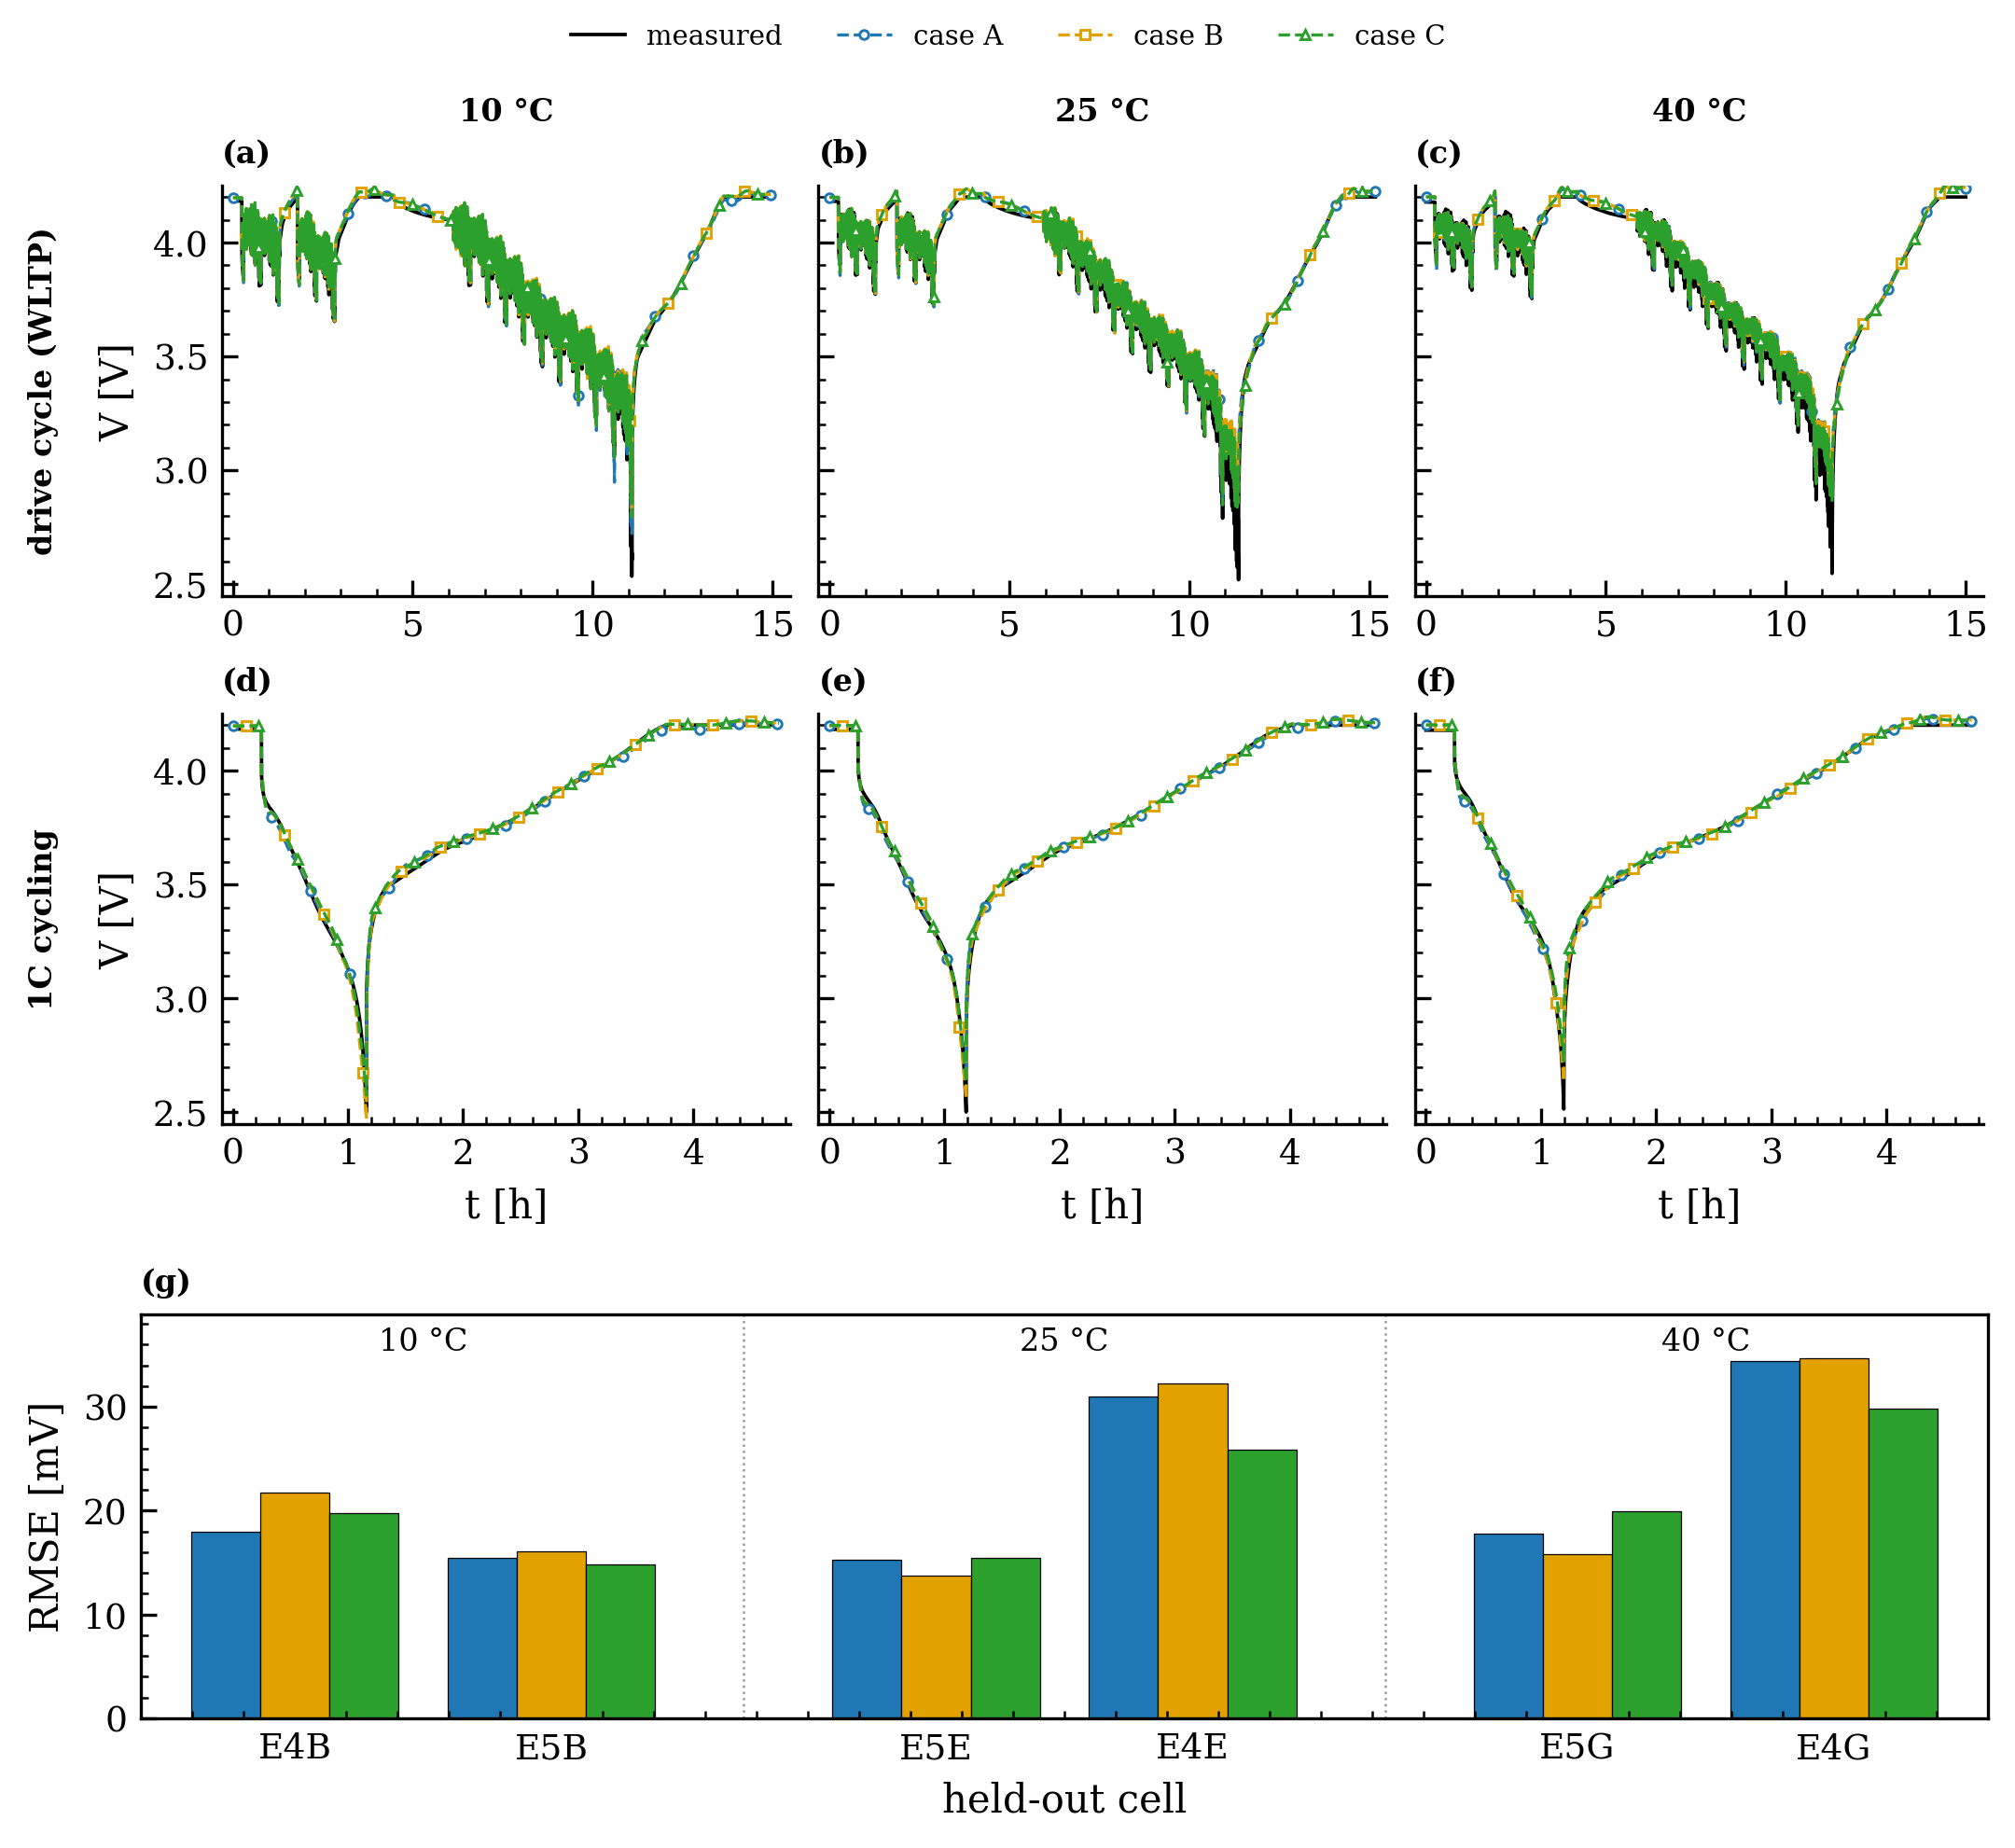

In [15]:
paper_figure('fig_lg_grid.py', 'fig10_lg_grid', '--cases', *['%s:%s' % kv for kv in LG.items()])